# Lab 1 - Part 1 : Regression with PyTorch (NYSE dataset)
Dataset : https://www.kaggle.com/datasets/dgawlik/nyse

The goal here is to predict the **close** price of a stock from the other columns of the day (open, low, high, volume).

In [1]:
# install the libs that are not in colab by default
!pip install -q skorch kagglehub


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from skorch import NeuralNetRegressor

torch.manual_seed(42)
np.random.seed(42)

## Load the data

In [3]:
import kagglehub, os
path = kagglehub.dataset_download("dgawlik/nyse")
print(os.listdir(path))

df = pd.read_csv(os.path.join(path, "prices-split-adjusted.csv"))
df.head()

C:\Users\Mounim Nadir\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['fundamentals.csv', 'prices-split-adjusted.csv', 'prices.csv', 'securities.csv']


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


## 1. Exploratory Data Analysis

In [4]:
print(df.shape)
df.info()

(851264, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    851264 non-null  object 
 1   symbol  851264 non-null  object 
 2   open    851264 non-null  float64
 3   close   851264 non-null  float64
 4   low     851264 non-null  float64
 5   high    851264 non-null  float64
 6   volume  851264 non-null  float64
dtypes: float64(5), object(2)
memory usage: 45.5+ MB


In [5]:
df.describe()

,open,close,low,high,volume
count,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,64.993618,65.011913,64.336541,65.639748,5.415113e+06
std,75.203893,75.201216,74.459518,75.906861,1.249468e+07
min,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08


In [6]:
# missing values and duplicates
print(df.isnull().sum())
print("duplicates :", df.duplicated().sum())

date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64


duplicates : 0


In [7]:
# how many companies and the date range
print("nb of symbols :", df["symbol"].nunique())
df["date"] = pd.to_datetime(df["date"])
print("from", df["date"].min(), "to", df["date"].max())

nb of symbols : 501
from 2010-01-04 00:00:00 to 2016-12-30 00:00:00


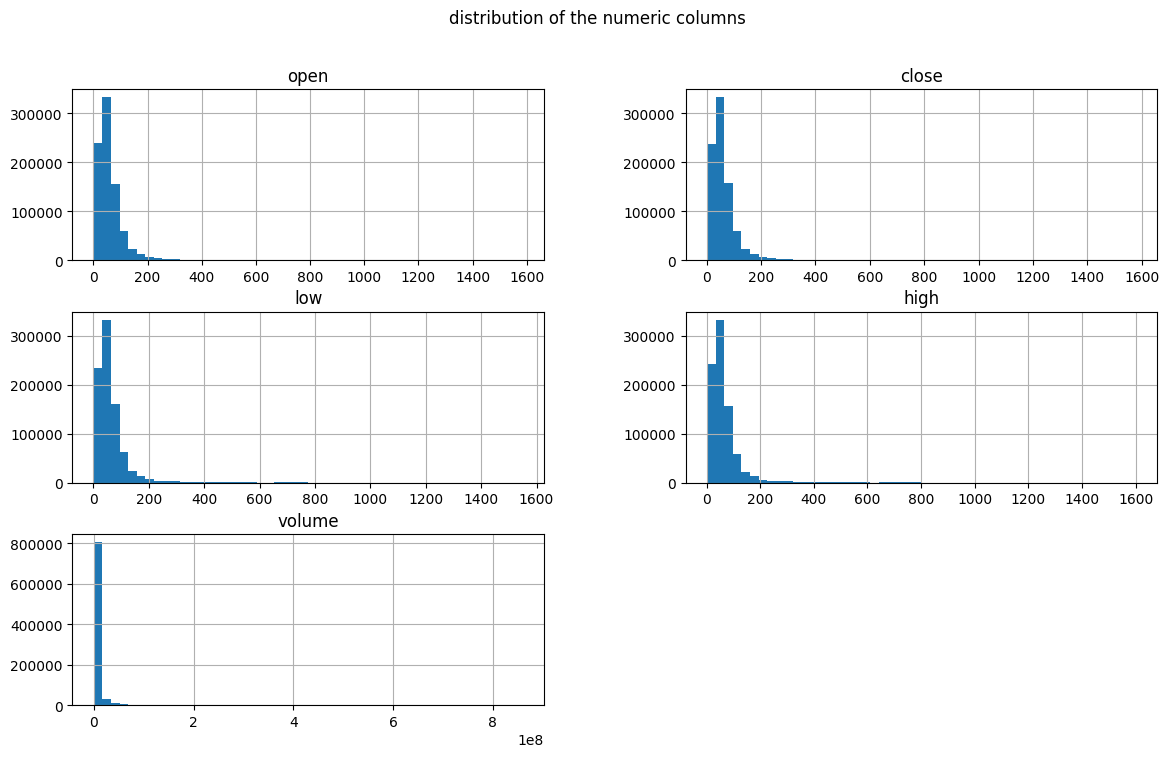

In [8]:
# distribution of each numeric column
cols = ["open", "close", "low", "high", "volume"]
df[cols].hist(bins=50, figsize=(14, 8))
plt.suptitle("distribution of the numeric columns")
plt.show()

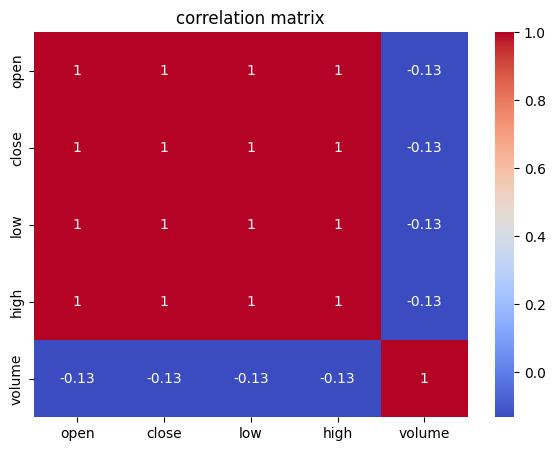

In [9]:
# correlation between the columns
plt.figure(figsize=(7, 5))
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm")
plt.title("correlation matrix")
plt.show()

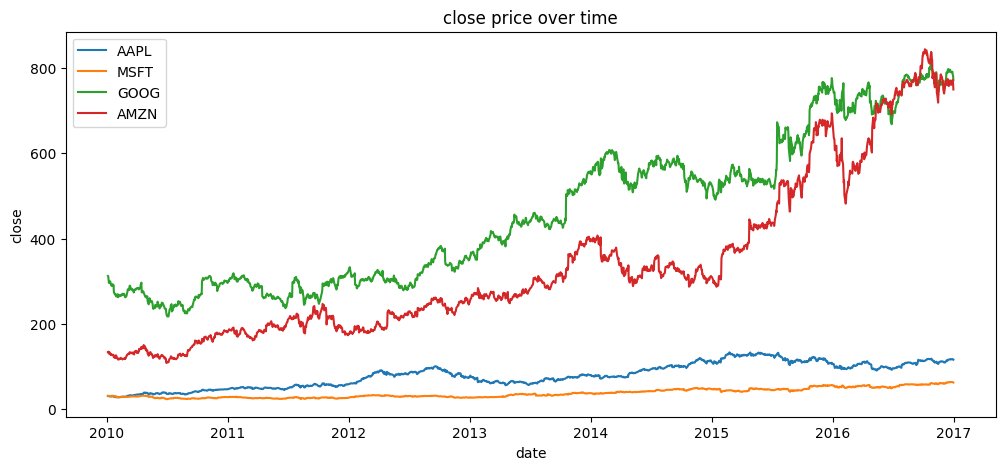

In [10]:
# close price over time for some known companies
plt.figure(figsize=(12, 5))
for s in ["AAPL", "MSFT", "GOOG", "AMZN"]:
    d = df[df["symbol"] == s]
    plt.plot(d["date"], d["close"], label=s)
plt.legend()
plt.title("close price over time")
plt.xlabel("date")
plt.ylabel("close")
plt.show()

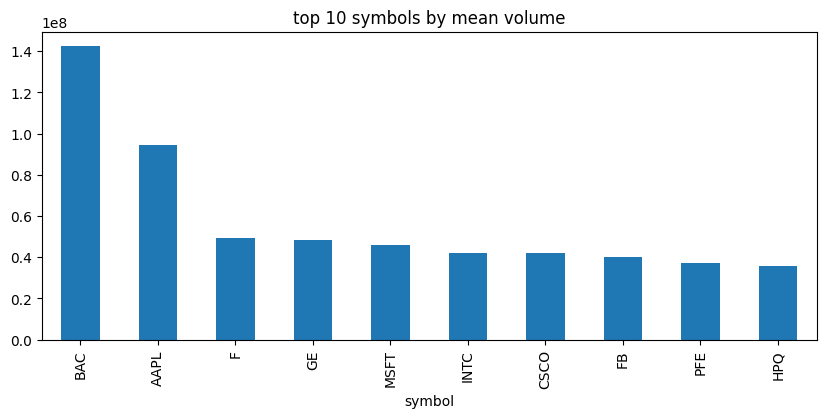

In [11]:
# top 10 companies by mean volume
top = df.groupby("symbol")["volume"].mean().sort_values(ascending=False).head(10)
top.plot(kind="bar", figsize=(10, 4), title="top 10 symbols by mean volume")
plt.show()

**What we see :** open, close, low and high are almost perfectly correlated (~1.0), the prices are very skewed
(lot of small prices, few very big ones) and volume is not really correlated with the price.
So we will use a log transform on the volume and standardize everything before training.

## Preprocessing

In [12]:
# the dataset is big (850k rows) so i take a sample to train faster
data = df.sample(50000, random_state=42).copy()

data["volume"] = np.log1p(data["volume"])

X = data[["open", "low", "high", "volume"]].values
y = data["close"].values.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# scale X and y (fit only on train)
sx = StandardScaler()
sy = StandardScaler()
X_train = sx.fit_transform(X_train)
X_test = sx.transform(X_test)
y_train = sy.fit_transform(y_train)
y_test = sy.transform(y_test)

X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)
y_train = y_train.astype(np.float32)
y_test = y_test.astype(np.float32)

print(X_train.shape, X_test.shape)

(40000, 4) (10000, 4)


## 2. DNN architecture with PyTorch

In [13]:
class RegNet(nn.Module):
    def __init__(self, n_in=4, hidden=64, n_layers=2, dropout=0.0, batchnorm=False):
        super().__init__()
        layers = []
        size = n_in
        for i in range(n_layers):
            layers.append(nn.Linear(size, hidden))
            if batchnorm:
                layers.append(nn.BatchNorm1d(hidden))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            size = hidden
        layers.append(nn.Linear(size, 1))  # 1 output = the close price
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

print(RegNet())

RegNet(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


## 3. GridSearch for the best hyper-parameters
We use **skorch** so the pytorch model can be used inside sklearn GridSearchCV.

In [14]:
net = NeuralNetRegressor(
    RegNet,
    criterion=nn.MSELoss,
    batch_size=256,
    verbose=0,
)

params = {
    "lr": [0.01, 0.001],
    "optimizer": [torch.optim.Adam, torch.optim.SGD],
    "max_epochs": [20, 40],
    "module__hidden": [32, 64],
    "module__n_layers": [2, 3],
}

# small subset for the grid search so it doesnt take forever
gs = GridSearchCV(net, params, cv=3, scoring="r2", n_jobs=1, verbose=1)
gs.fit(X_train[:10000], y_train[:10000])

print("best params :", gs.best_params_)
print("best r2 (cv) :", gs.best_score_)

Fitting 3 folds for each of 32 candidates, totalling 96 fits


best params : {'lr': 0.001, 'max_epochs': 40, 'module__hidden': 32, 'module__n_layers': 2, 'optimizer': <class 'torch.optim.adam.Adam'>}
best r2 (cv) : 0.9997940262158712


In [15]:
# show the results of all combinations
res = pd.DataFrame(gs.cv_results_)
res[["params", "mean_test_score"]].sort_values("mean_test_score", ascending=False).head(10)

,params,mean_test_score
24,"{'lr': 0.001, 'max_epochs': 40, 'module__hidde...",0.999794
26,"{'lr': 0.001, 'max_epochs': 40, 'module__hidde...",0.999787
20,"{'lr': 0.001, 'max_epochs': 20, 'module__hidde...",0.999785
28,"{'lr': 0.001, 'max_epochs': 40, 'module__hidde...",0.999779
22,"{'lr': 0.001, 'max_epochs': 20, 'module__hidde...",0.999773
18,"{'lr': 0.001, 'max_epochs': 20, 'module__hidde...",0.999734
30,"{'lr': 0.001, 'max_epochs': 40, 'module__hidde...",0.999675
16,"{'lr': 0.001, 'max_epochs': 20, 'module__hidde...",0.999654
0,"{'lr': 0.01, 'max_epochs': 20, 'module__hidden...",0.999644
10,"{'lr': 0.01, 'max_epochs': 40, 'module__hidden...",0.999375


## 4. Train the best model and plot Loss / Epochs and Accuracy / Epochs
For regression there is no real accuracy, so we use the **R² score** as accuracy.

In [16]:
def train_model(model, optimizer, epochs, X_train, y_train, X_test, y_test, batch_size=256, l1=0.0):
    loss_fn = nn.MSELoss()
    Xtr = torch.tensor(X_train); ytr = torch.tensor(y_train)
    Xte = torch.tensor(X_test); yte = torch.tensor(y_test)

    hist = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch_size):
            idx = perm[i:i + batch_size]
            pred = model(Xtr[idx])
            loss = loss_fn(pred, ytr[idx])
            # l1 regularization (if l1 > 0)
            if l1 > 0:
                loss = loss + l1 * sum(p.abs().sum() for p in model.parameters())
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # evaluate on train and test after each epoch
        model.eval()
        with torch.no_grad():
            ptr = model(Xtr); pte = model(Xte)
            hist["train_loss"].append(loss_fn(ptr, ytr).item())
            hist["test_loss"].append(loss_fn(pte, yte).item())
            hist["train_acc"].append(r2_score(y_train, ptr.numpy()))
            hist["test_acc"].append(r2_score(y_test, pte.numpy()))

        if ep % 10 == 0 or ep == epochs - 1:
            print(f"epoch {ep} | train loss {hist['train_loss'][-1]:.5f} | test loss {hist['test_loss'][-1]:.5f} | test r2 {hist['test_acc'][-1]:.4f}")
    return hist


def plot_hist(hist, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(hist["train_loss"], label="train")
    ax[0].plot(hist["test_loss"], label="test")
    ax[0].set_title("Loss / Epochs " + title); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist["train_acc"], label="train")
    ax[1].plot(hist["test_acc"], label="test")
    ax[1].set_title("Accuracy (R2) / Epochs " + title); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.show()

epoch 0 | train loss 0.00103 | test loss 0.00103 | test r2 0.9990


epoch 10 | train loss 0.00016 | test loss 0.00018 | test r2 0.9998


epoch 20 | train loss 0.00013 | test loss 0.00014 | test r2 0.9999


epoch 30 | train loss 0.00019 | test loss 0.00020 | test r2 0.9998


epoch 39 | train loss 0.00011 | test loss 0.00012 | test r2 0.9999


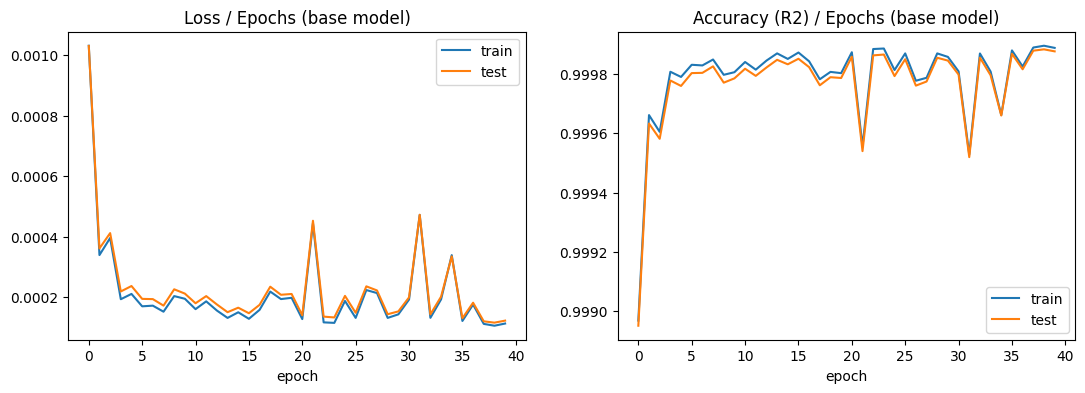

In [17]:
bp = gs.best_params_
model1 = RegNet(hidden=bp["module__hidden"], n_layers=bp["module__n_layers"])
opt1 = bp["optimizer"](model1.parameters(), lr=bp["lr"])

hist1 = train_model(model1, opt1, bp["max_epochs"], X_train, y_train, X_test, y_test)
plot_hist(hist1, "(base model)")

{'model': 'base', 'MSE': 0.6587361097335815, 'MAE': 0.4661928713321686, 'R2': 0.9998756051063538}


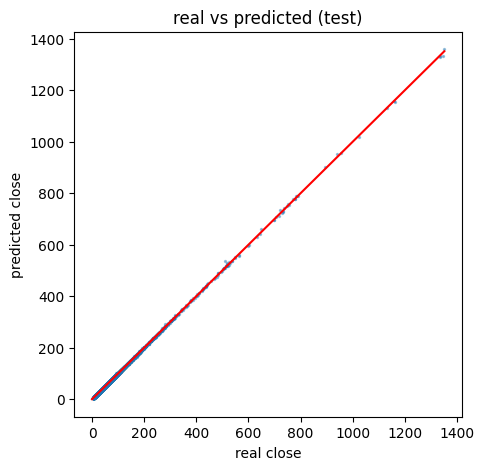

In [18]:
def evaluate(model, name):
    model.eval()
    with torch.no_grad():
        p = model(torch.tensor(X_test)).numpy()
    # go back to the real price scale
    p_real = sy.inverse_transform(p)
    y_real = sy.inverse_transform(y_test)
    r = {
        "model": name,
        "MSE": mean_squared_error(y_real, p_real),
        "MAE": mean_absolute_error(y_real, p_real),
        "R2": r2_score(y_real, p_real),
    }
    return r, p_real, y_real

r1, p_real, y_real = evaluate(model1, "base")
print(r1)

plt.figure(figsize=(5, 5))
plt.scatter(y_real, p_real, s=2, alpha=0.4)
plt.plot([0, y_real.max()], [0, y_real.max()], "r")
plt.xlabel("real close"); plt.ylabel("predicted close")
plt.title("real vs predicted (test)")
plt.show()

**Interpretation :** the loss goes down very fast in the first epochs and then becomes almost flat, train and test
curves are very close to each other so there is no real overfitting. The R² is close to 1 because close is
very correlated with open/low/high, so the task is "easy" for the network.

## 5. Regularization techniques
We try : Dropout, L2 (weight decay), L1, BatchNorm and all together, then compare with the base model.

In [19]:
results = [r1]
histories = {"base": hist1}
E = bp["max_epochs"]
OPT = bp["optimizer"]

configs = {
    "dropout":   dict(dropout=0.2, batchnorm=False, wd=0.0, l1=0.0),
    "L2":        dict(dropout=0.0, batchnorm=False, wd=1e-3, l1=0.0),
    "L1":        dict(dropout=0.0, batchnorm=False, wd=0.0, l1=1e-5),
    "batchnorm": dict(dropout=0.0, batchnorm=True,  wd=0.0, l1=0.0),
    "all":       dict(dropout=0.2, batchnorm=True,  wd=1e-3, l1=1e-5),
}

for name, c in configs.items():
    print("=====", name)
    m = RegNet(hidden=bp["module__hidden"], n_layers=bp["module__n_layers"], dropout=c["dropout"], batchnorm=c["batchnorm"])
    o = OPT(m.parameters(), lr=bp["lr"], weight_decay=c["wd"])
    h = train_model(m, o, E, X_train, y_train, X_test, y_test, l1=c["l1"])
    histories[name] = h
    results.append(evaluate(m, name)[0])

===== dropout
epoch 0 | train loss 0.01046 | test loss 0.01037 | test r2 0.9894


epoch 10 | train loss 0.01216 | test loss 0.01196 | test r2 0.9878


epoch 20 | train loss 0.02967 | test loss 0.02908 | test r2 0.9704


epoch 30 | train loss 0.02849 | test loss 0.02792 | test r2 0.9716


epoch 39 | train loss 0.02015 | test loss 0.01973 | test r2 0.9799
===== L2
epoch 0 | train loss 0.00207 | test loss 0.00208 | test r2 0.9979


...

epoch 0 | train loss 0.00839 | test loss 0.00833 | test r2 0.9915


epoch 10 | train loss 0.00560 | test loss 0.00544 | test r2 0.9945


epoch 20 | train loss 0.02884 | test loss 0.02806 | test r2 0.9714


epoch 30 | train loss 0.01459 | test loss 0.01447 | test r2 0.9853


epoch 39 | train loss 0.01277 | test loss 0.01283 | test r2 0.9869


In [20]:
pd.DataFrame(results)

,model,MSE,MAE,R2
0,base,0.658736,0.466193,0.999876
1,dropout,106.335266,3.141391,0.979919
2,L2,1.301627,0.583393,0.999754
3,L1,0.962950,0.552094,0.999818
4,batchnorm,18.624237,3.192393,0.996483
5,all,69.113380,6.930512,0.986948


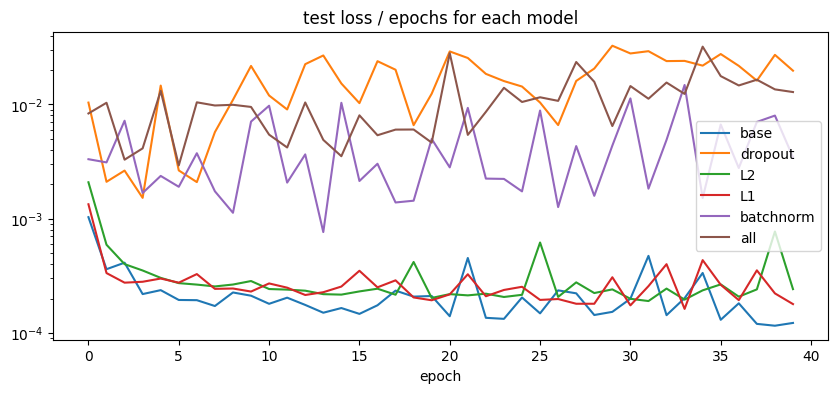

In [21]:
# compare the test loss of all models
plt.figure(figsize=(10, 4))
for name, h in histories.items():
    plt.plot(h["test_loss"], label=name)
plt.yscale("log")
plt.title("test loss / epochs for each model")
plt.xlabel("epoch"); plt.legend()
plt.show()

**Comparison :** the base model was already not overfitting (R² ≈ 0.9999 on test), so regularization does not help here.
L1 and L2 give almost the same result as the base model (small weights, same R²). Dropout and BatchNorm make the
results worse (bigger MSE / MAE) : dropout adds noise to a model that needs to be very precise, and batchnorm makes
the test predictions less stable. Regularization is useful when there is a big gap between train and test, which is not the case here.